# Step 4: Semantic NLP (Sentence Transformers) and main evaluation
**Member 4 (Tao Lou).** Question: can embeddings recover skills a job ad *implies* but never names, without hurting
precision, compared with Step 3's Baseline++? All logic lives in the `.py` files; this notebook runs and displays it.
Run all cells top to bottom (first run downloads the models; about 10-30 min on CPU for all four models).

In [1]:
# ---- Setup: find Step 3 (step3_baseline_nlp/ next to this folder, or set STEP3_DIR) -----------------------
import os, sys, warnings; warnings.filterwarnings("ignore", category=FutureWarning)
sys.path.insert(0, os.getcwd())
import pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 110)
import config, experiments as ex, metrics
from data_access import load_context, verify_against_step3
ctx = load_context()              # raises a clear error if Step 3 cannot be found
runner = ex.Runner(ctx)           # device auto-detected by sentence-transformers (pass device="cuda" if available)
print("Step 3:", ctx.step3, "| gold ads:", len(ctx.rows), "| skills in universe:", len(ctx.universe))

Step 3: /Users/lemontoast/Documents/1/Member3_Baseline_NLP | gold ads: 30 | skills in universe: 158


## 1. Sanity check: our metric code reproduces Step 3 (S0 F1 0.872, S5 F1 0.943)

In [2]:
v = verify_against_step3(ctx)
ex.baseline_table(ctx).round(3)

,system,strict_TP,strict_FP,strict_FN,strict_P,strict_R,strict_F1,lenient_TP,lenient_FP,lenient_FN,lenient_P,lenient_R,lenient_F1,I_recall,n_added,added_per_ad,added_correct,added_I,added_precision
0,S0 Baseline (PhraseMatcher),211,23,39,0.902,0.844,0.872,212,22,81,0.906,0.724,0.805,0.023,6,0.2,1,0,0.167
1,S5 Baseline++,246,26,4,0.904,0.984,0.943,247,25,46,0.908,0.843,0.874,0.023,0,0.0,0,0,NaN


## 2. Model comparison (leave-one-ad-out tuning; pooled out-of-fold predictions)
`hashing` is a lexical control (no semantics). `semantic-only` drops the exact matcher. Main model fixed in advance: `mpnet`.
`mpnet hybrid (pool chosen in CV)` picks max vs centroid pooling inside each fold, so the held-out ad does not influence the choice; a check of the
centroid default, which was adopted after the first ablation.

In [3]:
table, boots, results = ex.model_comparison(runner, config.COMPARE_MODELS)
table[["system","tau_median","strict_F1","lenient_P","lenient_R","lenient_F1","I_recall","n_added","added_precision"]].round(3)

  -> hashing hybrid
  -> minilm hybrid
  -> mpnet hybrid
  -> mpnet semantic-only (all skills)
  -> mpnet hybrid (pool chosen in CV)
     pool chosen per held-out ad: centroid 30/30
  -> bge-base hybrid


,system,tau_median,strict_F1,lenient_P,lenient_R,lenient_F1,I_recall,n_added,added_precision
0,hashing hybrid,0.65,0.943,0.908,0.843,0.874,0.023,0,NaN
1,minilm hybrid,0.63,0.920,0.891,0.867,0.879,0.186,13,0.538
2,mpnet hybrid,0.62,0.904,0.888,0.891,0.889,0.349,22,0.636
3,mpnet semantic-only (all skills),0.52,0.451,0.585,0.457,0.513,0.605,116,0.224
4,mpnet hybrid (pool chosen in CV),0.62,0.904,0.888,0.891,0.889,0.349,22,0.636
5,bge-base hybrid,0.79,0.909,0.887,0.881,0.884,0.279,19,0.579


In [4]:
# paired bootstrap of every system vs Baseline++ (95% CI of the difference)
b = ex.flatten_ci(boots)
b[(b.vs == ex.S5)][["system","metric","a","b","delta","delta_lo","delta_hi","p_delta_le_0"]].round(3)

,system,metric,a,b,delta,delta_lo,delta_hi,p_delta_le_0
0,hashing hybrid,strict_F1,0.943,0.943,0.000,0.000,0.000,1.000
1,hashing hybrid,lenient_F1,0.874,0.874,0.000,0.000,0.000,1.000
2,hashing hybrid,lenient_P,0.908,0.908,0.000,0.000,0.000,1.000
3,hashing hybrid,I_recall,0.023,0.023,0.000,0.000,0.000,1.000
4,hashing hybrid,strict_F1 (Step 3 evaluate.bootstrap),0.943,0.943,0.000,0.000,0.000,1.000
10,minilm hybrid,strict_F1,0.943,0.920,-0.023,-0.041,-0.009,1.000
11,minilm hybrid,lenient_F1,0.874,0.879,0.005,-0.009,0.018,0.256
12,minilm hybrid,lenient_P,0.908,0.891,-0.017,-0.039,-0.000,0.980
13,minilm hybrid,I_recall,0.023,0.186,0.163,0.057,0.282,0.002
14,minilm hybrid,strict_F1 (Step 3 evaluate.bootstrap),0.943,0.920,-0.023,-0.041,-0.009,1.000


**How to read it.** *Strict* uses Step 3's gold (R+P): valid implicit skills count as errors, and Baseline++ already
has strict recall 0.984, so strict F1 cannot improve much. *Lenient* (R+P+I) is the fair view for a method built to find
implicit skills; *I-recall* is the share of the 43 implicit labels recovered.

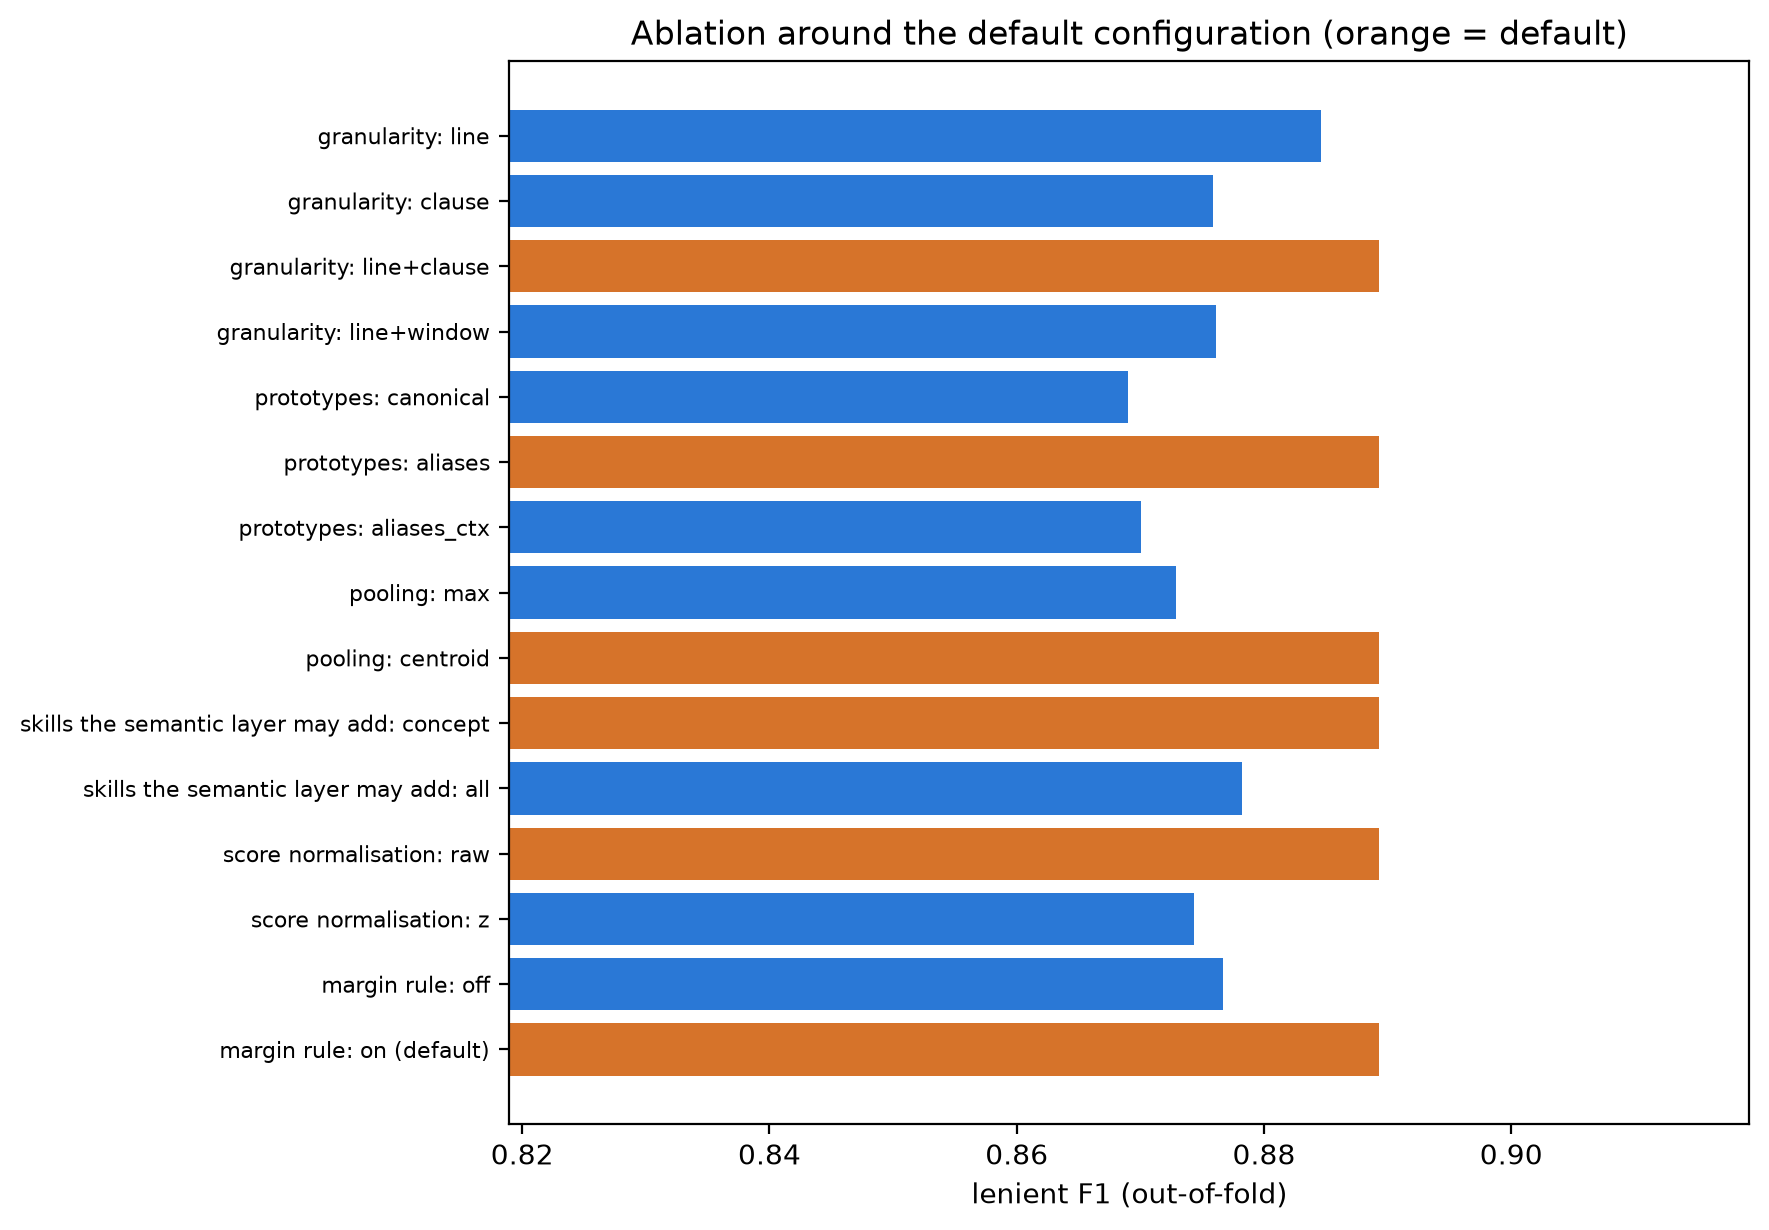

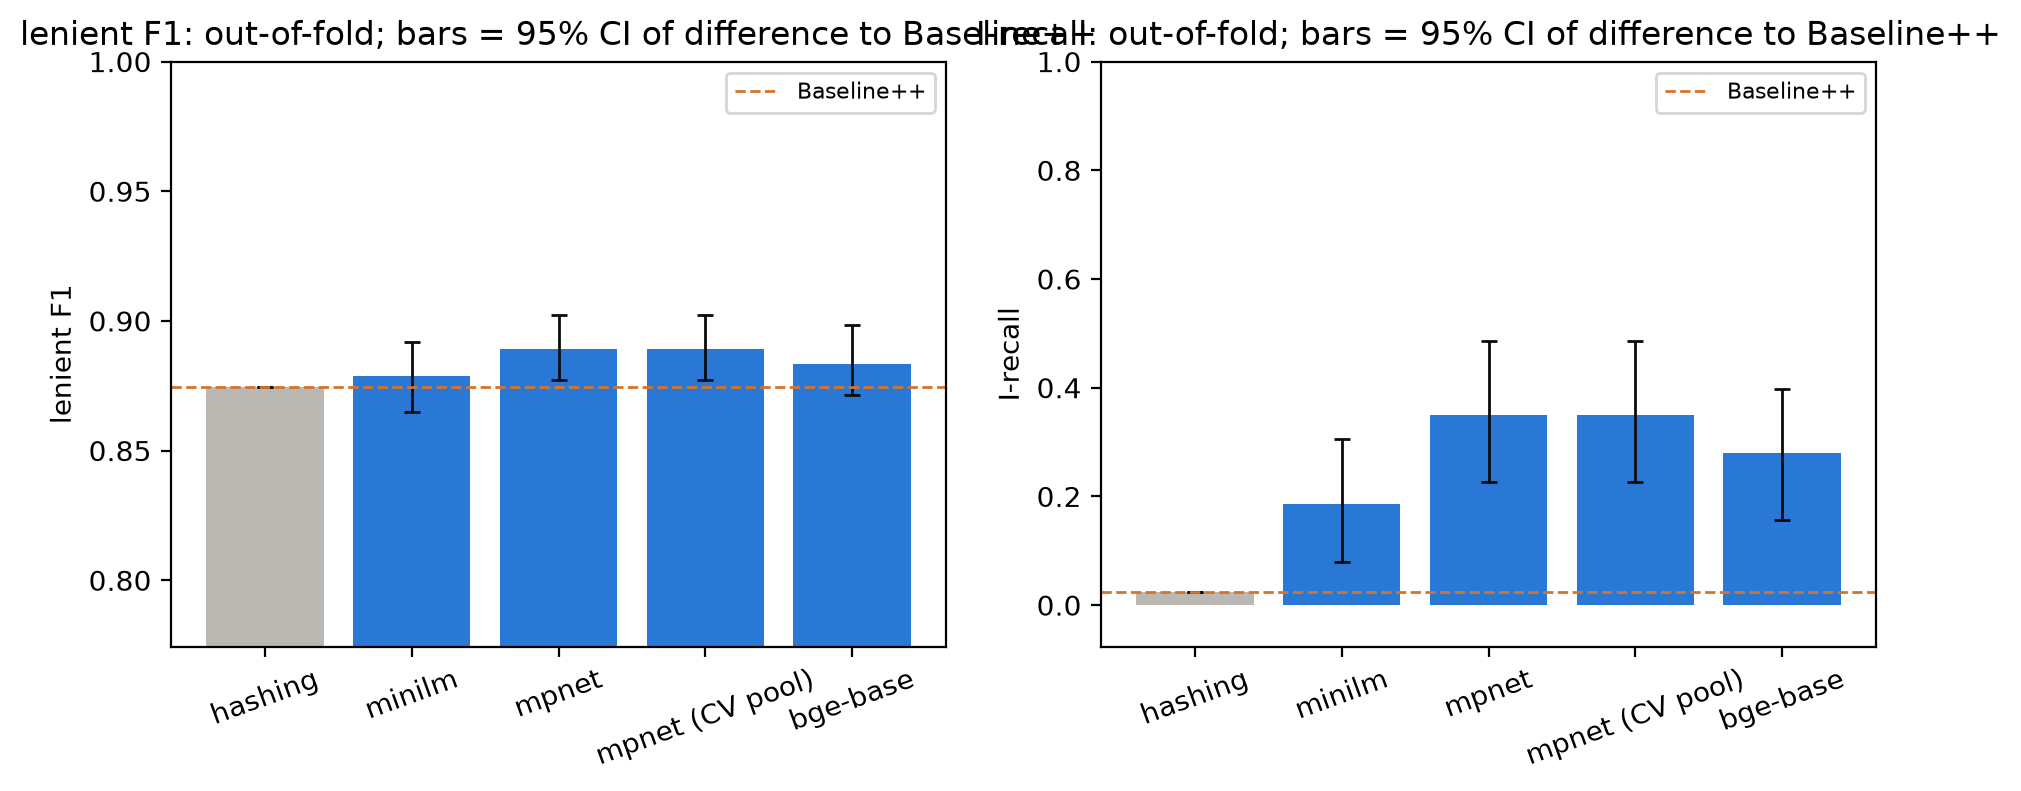

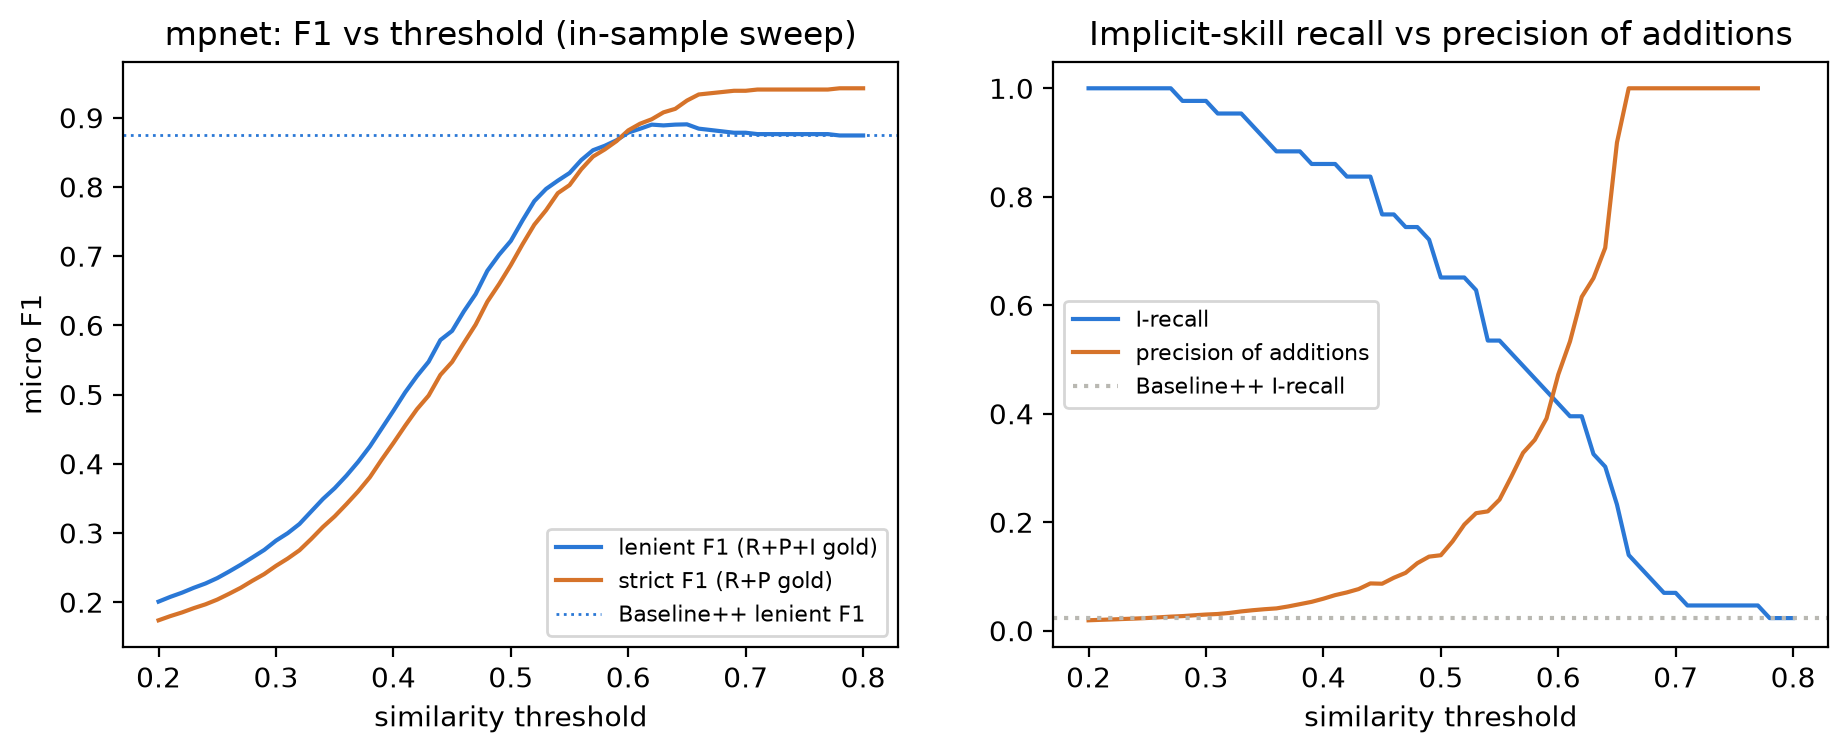

In [5]:
# threshold sweep for the main model (shows how flat/peaked the optimum is) and model comparison figures
import figures as fg
main = results[f"{config.MAIN_MODEL} hybrid"]
base = ex.baseline_table(ctx).set_index("system").loc[ex.S5]
fg.fig_threshold_sweep(main["sweep"], config.MAIN_MODEL, base["lenient_F1"], base["I_recall"])
fg.fig_model_comparison(table, b, base)
from IPython.display import Image, display
for f in sorted(config.FIGURES.glob("fig_s4_*.png")): display(Image(str(f)))

## 3. Ablation (one factor at a time around the default configuration, main model)

In [6]:
abl, abl_boot = ex.ablation(runner, config.MAIN_MODEL)
fg.fig_ablation(abl)
abl[["factor","setting","tau_median","strict_F1","lenient_P","lenient_R","lenient_F1","I_recall","n_added","added_precision"]].round(3)

  -> granularity line
  -> granularity clause
  -> granularity line+clause
  -> granularity line+window
  -> prototypes canonical
  -> prototypes aliases
  -> prototypes aliases_ctx
  -> pooling max
  -> pooling centroid
  -> skills the semantic layer may add concept
  -> skills the semantic layer may add all
  -> score normalisation raw
  -> score normalisation z
  -> margin rule off
  -> margin rule on (default)


,factor,setting,tau_median,strict_F1,lenient_P,lenient_R,lenient_F1,I_recall,n_added,added_precision
0,granularity,line,0.62,0.930,0.907,0.863,0.885,0.163,7,0.857
1,granularity,clause,0.62,0.916,0.885,0.867,0.876,0.186,15,0.467
2,granularity,line+clause,0.62,0.904,0.888,0.891,0.889,0.349,22,0.636
3,granularity,line+window,0.61,0.928,0.896,0.857,0.876,0.116,8,0.500
4,prototypes,canonical,0.62,0.916,0.878,0.860,0.869,0.140,15,0.333
5,prototypes,aliases,0.62,0.904,0.888,0.891,0.889,0.349,22,0.636
6,prototypes,aliases_ctx,0.68,0.921,0.884,0.857,0.870,0.116,12,0.333
7,pooling,max,0.65,0.913,0.879,0.867,0.873,0.186,17,0.412
8,pooling,centroid,0.62,0.904,0.888,0.891,0.889,0.349,22,0.636
9,skills the semantic layer may add,concept,0.62,0.904,0.888,0.891,0.889,0.349,22,0.636


## 4. Error analysis: which implicit skills are recovered, missed, and which additions are wrong

In [7]:
import error_analysis as ea
err, by = ea.error_table(runner, main)
ea.save(err, by)
print(err.kind.value_counts().to_string())
err[err.kind == "addition_wrong"].sort_values("cosine", ascending=False).head(15)[["row","skill","cosine","strength","evidence"]]

kind
I_missed                   28
I_recovered_by_semantic    14
addition_correct_I         14
addition_wrong              8
I_found_by_exact            1


,row,skill,cosine,strength,evidence
61,537,Data Warehousing,0.656839,required,Hands-on experience with at least one area of market data infrastructure
9,65,Data Cleaning,0.649967,duty,clean data models.
11,65,Data Quality,0.644529,duty,"Establish high data integrity standards and SLAs to ensure timely, accurate delivery of data"
32,215,Model Deployment,0.643929,duty,Operating across models
28,208,Data Pipelines,0.642527,preferred,ML pipeline and automation engineering
38,302,Data Warehousing,0.630897,duty,and engineering to advocate best practices and build supporting systems and infrastructure for the various...
26,182,Data Modeling,0.624843,preferred,Knowledge of data engineering
59,527,AI Agents,0.623313,duty,Partner with AI


In [8]:
err[err.kind.str.startswith("I_missed")].head(15)[["row","skill","kind","cosine","evidence"]]

,row,skill,kind,cosine,evidence
2,9,Statistics,I_missed,0.536705,Strong statistical knowledge
3,57,Experiment Design,I_missed,0.445384,with a track record designing and interpreting A/B tests and quasi-experiments
4,57,Statistics,I_missed,0.496165,As a Data Scientist on FinEng
8,65,Data Visualization,I_missed,0.535514,Experience building data reporting and dashboarding in visualization tools like Hex to serve multiple cros...
15,106,Experiment Design,I_missed,0.533293,Design evaluation strategies
16,106,Model Deployment,I_missed,0.443619,"Apply and adapt foundation-model capabilities to real product workflows (LLM + tools/RAG, multimodal model..."
17,106,Model Evaluation,I_missed,0.480634,Design evaluation strategies
18,106,Recommendation Systems,I_missed,0.598627,Experience with personalization systems
22,158,Model Deployment,I_missed,0.334404,"You'll partner closely with engineering, product, and data science to ship models and algorithms that dire..."
23,170,Model Training,I_missed,0.534688,Experience with large-scale distributed training


## 5. Save results, run the 688-ad corpus and the 20 unit PDFs
These steps write the files Student 5 uses and the **blinded** audit sheets (`docs/audit_instructions.md`).
Sheets that already contain labels are never overwritten.

In [9]:
import json
from dataclasses import asdict
config.ensure_dirs(); D, A, H = config.DETAILS, config.AUDIT, config.HANDOFF
table.to_csv(D/"model_comparison.csv", index=False); b.to_csv(D/"model_bootstrap.csv", index=False)
abl.to_csv(D/"ablation.csv", index=False); ex.baseline_table(ctx).to_csv(D/"baseline_table.csv", index=False)
ex.all_sweeps(results).to_csv(D/"sweeps.csv", index=False)
ex.save_json(dict(model=main["model"], cfg=main["cfg"], decision=asdict(main["insample_decision"])), D/"final_config.json")
import corpus_extract as ce
print(ce.run(runner, ce.load_final()))

  NOTE: job_audit_sheet.csv already has labels - not overwritten (delete it to make a new sheet)
{'n_ads': 688, 'n_exact': 7282, 'n_semantic': 479, 'ads_with_addition': 332}


In [10]:
import curriculum_semantic as cs
hy = ce.build_hybrid(runner, ce.load_final())
exact_p, hyb_p, man, adds = cs.load_curriculum_hybrid(ctx.step3, hy.space, hy.encoder, hy.decision, hy.granularity)
runner.save()
adds.to_csv(D/"curriculum_semantic_additions.csv", index=False)
if not ce._has_labels(A/"curriculum_label_sheet.csv"):      # never overwrite labels you already made
    sheet, key = cs.label_sheet(exact_p, hyb_p)
    sheet.to_csv(A/"curriculum_label_sheet.csv", index=False)
    key.to_csv(A/"curriculum_label_key.csv", index=False)   # keep hidden from the annotator
cs.all_hits(exact_p, hyb_p).to_csv(D/"curriculum_all_hits.csv", index=False)
summ = pd.DataFrame([dict(unit_id=u, n_exact=len(exact_p[u].skills), n_semantic_added=len(hyb_p[u].skills)-len(exact_p[u].skills),
                          added=", ".join(sorted(set(hyb_p[u].skills)-set(exact_p[u].skills)))) for u in exact_p])
summ.to_csv(D/"curriculum_unit_summary.csv", index=False)
ex.save_json(cs.named_checks(exact_p, hyb_p, man), D/"curriculum_named_checks.json")
display(summ)
pd.DataFrame(cs.named_checks(exact_p, hyb_p, man))

,unit_id,n_exact,n_semantic_added,added
0,UTS 36100 Data Science for Innovation,4,3,"Data Analysis, Data Cleaning, Hypothesis Testing"
1,UTS 36103 Statistical Thinking,2,1,Statistics
2,UTS 36104 Data Visualisation and Narratives,1,0,
3,UTS 36106 ML Algorithms,1,0,
4,UTS 36117 Data Visualisation,1,0,
5,UTS 36118 Applied NLP,2,0,
6,UTS 36120 Adv ML Application,3,0,
7,UTS 36124 Applied Data Science for Innovation,6,0,
8,UTS 41091 Data Systems,3,1,Data Warehousing
9,UTS 94693 Big Data Engineering,14,0,


,unit,skill,exact_found,hybrid_found,n_exact_skills,n_hybrid_skills,evidence,page,score
0,UNSW COMP9311 Database Systems,SQL,False,False,0,1,NaN,NaN,NaN
1,UTS 36103 Statistical Thinking,Statistics,False,True,2,3,This subject instills the statistical thinking central to data science,1.0,0.70513


In [11]:
cs.career_fit_comparison(ctx.step3, ctx.jobs, ctx.s5, hy, exact_p, hyb_p)

,career,exact_fit,exact_lo,exact_hi,exact_n_skills_covered,hybrid_fit,hybrid_lo,hybrid_hi,hybrid_n_skills_covered
0,AI Engineer,0.326,0.316,0.380,39,0.408,0.390,0.454,43
1,Data Analyst,0.581,0.505,0.622,39,0.626,0.554,0.660,43
2,Data Engineer,0.593,0.538,0.611,39,0.629,0.570,0.645,43
3,Data Scientist,0.654,0.627,0.691,39,0.685,0.647,0.711,43
4,ML Engineer,0.582,0.548,0.632,39,0.624,0.577,0.657,43


## 6. Blinded human audit
Both sheets were labelled with `label_tool.py` (100 job-ad items, 52 unit-PDF items; source hidden during labelling).
Precision, semantic vs exact: job ads 0.64 vs 0.96, unit PDFs 0.77 vs 0.97 (Wilson 95% intervals in `results/summary.md`).
Re-score with `ce.evaluate_job_audit()` and `cs.evaluate_unit_labels()`.